In [5]:
import pandas as pd

matches = pd.read_csv('../data/matches.csv')
deliveries = pd.read_csv('../data/deliveries.csv')

matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [6]:
matches.shape

(1095, 20)

In [7]:
deliveries.shape

(260920, 17)

In [8]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [9]:
deliveries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

In [10]:
matches.columns

Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
       'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
       'method', 'umpire1', 'umpire2'],
      dtype='object')

In [11]:
deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

In [12]:
matches.isnull().sum()

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

In [13]:
deliveries.isnull().sum()

match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

In [14]:
matches.duplicated().sum()

np.int64(0)

In [15]:
team_wins = matches['winner'].value_counts()

team_wins.head(10)

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Rajasthan Royals               112
Kings XI Punjab                 88
Sunrisers Hyderabad             88
Delhi Daredevils                67
Delhi Capitals                  48
Deccan Chargers                 29
Name: count, dtype: int64

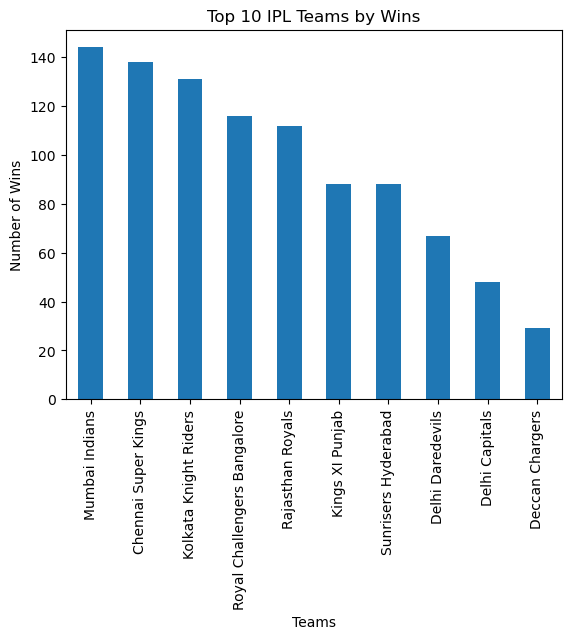

In [16]:
import matplotlib.pyplot as plt

team_wins.head(10).plot(kind='bar')

plt.title('Top 10 IPL Teams by Wins')
plt.xlabel('Teams')
plt.ylabel('Number of Wins')

plt.show()

Mumbai Indians and Chennai Super Kings are among the most successful teams in IPL history.

In [17]:
(matches['toss_winner'] == matches['winner']).sum()

np.int64(554)

In [18]:
total_matches = len(matches)

toss_match_wins = (matches['toss_winner'] == matches['winner']).sum()

percentage = (toss_match_wins / total_matches) * 100

print(percentage)

50.593607305936075


Toss winners won approximately 50.593607305936075% of matches, suggesting that winning the toss has a moderate influence on match outcomes.

In [19]:
top_runs = deliveries.groupby('batter')['batsman_runs'].sum()

top_runs.sort_values(ascending=False).head(10)

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64

In [20]:
deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

In [21]:
matches.drop_duplicates(inplace=True)
deliveries.drop_duplicates(inplace=True)

In [22]:
matches['winner'].unique()

array(['Kolkata Knight Riders', 'Chennai Super Kings', 'Delhi Daredevils',
       'Royal Challengers Bangalore', 'Rajasthan Royals',
       'Kings XI Punjab', 'Deccan Chargers', 'Mumbai Indians',
       'Pune Warriors', 'Kochi Tuskers Kerala', nan,
       'Sunrisers Hyderabad', 'Rising Pune Supergiants', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings',
       'Gujarat Titans', 'Lucknow Super Giants',
       'Royal Challengers Bengaluru'], dtype=object)

In [23]:
powerplay = deliveries[deliveries['over'] <= 6]

In [24]:
death = deliveries[deliveries['over'] >= 16]

In [25]:
fours = deliveries[deliveries['batsman_runs'] == 4]

top_fours = fours.groupby('batter').size()

top_fours.sort_values(ascending=False).head(10)

batter
S Dhawan        768
V Kohli         708
DA Warner       663
RG Sharma       599
SK Raina        506
G Gambhir       492
RV Uthappa      481
AM Rahane       479
KD Karthik      466
F du Plessis    422
dtype: int64

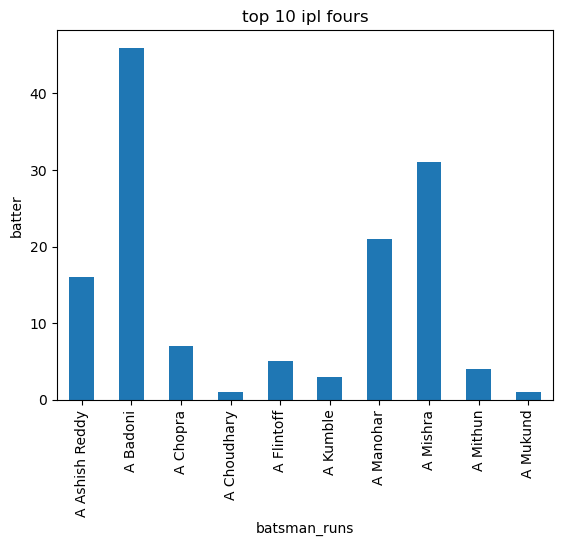

In [26]:
import matplotlib.pyplot as plt

top_fours.head(10).plot(kind='bar')

plt.title('top 10 ipl fours')
plt.xlabel('batsman_runs')
plt.ylabel('batter')

plt.show()

In [27]:
sixes = deliveries[deliveries['batsman_runs'] == 6]

top_sixes = sixes.groupby('batter').size()

top_sixes.sort_values(ascending=False).head(10)


batter
CH Gayle          359
RG Sharma         281
V Kohli           273
AB de Villiers    253
MS Dhoni          252
DA Warner         236
KA Pollard        224
AD Russell        209
SV Samson         206
SK Raina          204
dtype: int64

In [28]:
deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

In [29]:
wickets = deliveries[deliveries['player_dismissed'].notna()]

top_wickets = wickets.groupby('bowler').size()

top_wickets.sort_values(ascending=False).head(10)

bowler
YS Chahal     213
DJ Bravo      207
PP Chawla     201
SP Narine     200
R Ashwin      198
B Kumar       195
SL Malinga    188
A Mishra      183
JJ Bumrah     182
RA Jadeja     169
dtype: int64

In [30]:
runs_given = deliveries.groupby('bowler')['total_runs'].sum()

balls_bowled = deliveries.groupby('bowler').size()

overs_bowled = balls_bowled / 6

economy = runs_given / overs_bowled

economy.sort_values().head(10)

bowler
AC Gilchrist     0.000000
R Ravindra       3.500000
NB Singh         4.320000
Sachin Baby      4.800000
AM Rahane        5.000000
LA Carseldine    5.142857
SS Mundhe        5.142857
DJ Thornely      5.454545
M Manhas         6.000000
MW Short         6.000000
dtype: float64

In [31]:
powerplay.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(10)

batter
S Dhawan        3776
DA Warner       3648
V Kohli         3178
CH Gayle        2668
AM Rahane       2567
G Gambhir       2539
RG Sharma       2437
F du Plessis    2361
RV Uthappa      2353
KL Rahul        2260
Name: batsman_runs, dtype: int64

In [32]:
powerplay[powerplay['player_dismissed'].notna()]\
.groupby('bowler').size().sort_values(ascending=False).head(10)

bowler
B Kumar           77
Sandeep Sharma    66
UT Yadav          63
TA Boult          63
I Sharma          62
DL Chahar         61
Z Khan            59
R Ashwin          55
Mohammed Shami    51
P Kumar           48
dtype: int64

In [33]:
death.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(10)

batter
MS Dhoni          2786
KA Pollard        1708
KD Karthik        1565
AB de Villiers    1421
RA Jadeja         1420
RG Sharma         1176
HH Pandya         1126
V Kohli           1099
AD Russell        1065
DA Miller          988
Name: batsman_runs, dtype: int64

In [34]:
death[death['batsman_runs'] == 6]\
.groupby('batter').size().sort_values(ascending=False).head(10)

batter
MS Dhoni          175
KA Pollard        127
AB de Villiers    112
AD Russell         93
KD Karthik         91
HH Pandya          82
RG Sharma          79
V Kohli            71
RA Jadeja          69
DA Miller          60
dtype: int64

In [35]:
death[death['player_dismissed'].notna()]\
.groupby('bowler').size().sort_values(ascending=False).head(10)

bowler
DJ Bravo          115
SL Malinga        104
B Kumar            93
JJ Bumrah          89
HV Patel           74
MM Sharma          72
SP Narine          69
Mohammed Shami     69
CH Morris          61
R Vinay Kumar      58
dtype: int64

In [36]:
death[death['player_dismissed'].notna()]\
.groupby('bowler').size().sort_values(ascending=False).head(10)

bowler
DJ Bravo          115
SL Malinga        104
B Kumar            93
JJ Bumrah          89
HV Patel           74
MM Sharma          72
SP Narine          69
Mohammed Shami     69
CH Morris          61
R Vinay Kumar      58
dtype: int64

In [37]:
matches['venue'].value_counts().head(10)

venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      45
Punjab Cricket Association Stadium, Mohali    35
Name: count, dtype: int64

In [38]:
matches['player_of_match'].value_counts().head(10)

player_of_match
AB de Villiers    25
CH Gayle          22
RG Sharma         19
DA Warner         18
V Kohli           18
MS Dhoni          17
SR Watson         16
YK Pathan         16
RA Jadeja         16
AD Russell        15
Name: count, dtype: int64

In [39]:
print(matches.columns.tolist())

['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']


In [40]:
print(deliveries.columns.tolist())

['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


# Key Insights

1. The most successful IPL teams were identified based on total match wins.
2. Winning the toss had a measurable impact on match results.
3. Top batters were identified using total runs, strike rate, fours, and sixes.
4. Top bowlers were identified using wickets, economy rate, and death-over performance.
5. Powerplay and death-over analysis highlighted different player strengths.
6. Venue analysis showed which stadiums hosted the most IPL matches.
7. SQL queries were used to validate and extend the Python analysis.

- [V Kohli] scored the most runs in the dataset.
- [Mumbai Indians] won the highest number of matches with 144 wins
- Toss winners won approximately [50.83]% of matches.
- [YS Chahal] took the most wickets.
- [AB de Villiers] received the most Player of the Match awards with [25] awards.
- [S Dhawan] scored the most runs during powerplay overs with [3415] runs.
- [MS Dhoni] scored the most runs in death overs with [2786] runs.